# 07 · Dimensionality reduction and topics — LSA and LDA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/07_topic_models_lsa_lda.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 7 of 12*

TF-IDF vectors have one dimension per word: thousands of sparse, independent axes. "rocket" and "launch"
are as unrelated as "rocket" and "pitcher", so two posts that talk about the same thing with different
words look dissimilar. **Topic models** compress the vocabulary into a few dozen *latent* dimensions in
which words that tend to occur together are grouped. In this notebook we build the two classic ones:
**Latent Semantic Analysis (LSA)** — a truncated SVD of the TF-IDF matrix — and **Latent Dirichlet
Allocation (LDA)** — a probabilistic model of documents as mixtures of topics.

### Learning objectives
By the end of this notebook you will be able to:
1. Explain why sparse word-count vectors cannot capture synonymy, and what a latent dimension is.
2. Run LSA with `TruncatedSVD` on a TF-IDF matrix and interpret its components through their top words.
3. Project documents into a 2D LSA space and use LSA vectors for document retrieval.
4. Fit an LDA topic model on word counts, read its topics and per-document topic mixtures.
5. Check how unsupervised topics line up with the true newsgroup categories.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

## 1 · The data and the TF-IDF matrix
Same set-up as notebook 06: preprocessed newsgroup posts, TF-IDF fitted on the training split.
We drop words that appear in fewer than 5 posts (`min_df=5`) and in more than half of them (`max_df=0.5`);
topic models work better without very rare and very common words.

In [3]:
df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
test = df[df["subset"] == "test"].reset_index(drop=True)
train_tok = [nlp_course.preprocess(t) for t in train["text"]]
test_tok = [nlp_course.preprocess(t) for t in test["text"]]
y_train, y_test = train["category"].to_numpy(), test["category"].to_numpy()
identity = lambda tokens: tokens

tfidf = TfidfVectorizer(analyzer=identity, min_df=5, max_df=0.5)
W_train = tfidf.fit_transform(train_tok)
W_test = tfidf.transform(test_tok)
vocab = tfidf.get_feature_names_out()
print("train:", W_train.shape, " test:", W_test.shape)
print(f"non-zero entries: {W_train.nnz / np.prod(W_train.shape):.2%} of the matrix")

train: (2239, 4400)  test: (1490, 4400)
non-zero entries: 1.16% of the matrix


### The synonymy problem
In TF-IDF space each word is its own axis, so the cosine similarity of two *words* (columns) is just how
often they share documents. Two one-word "documents" made of related words have similarity exactly 0.

In [4]:
q = tfidf.transform([["rocket"], ["launch"], ["pitcher"]])
print("cosine(rocket, launch)  =", cosine_similarity(q[0], q[1])[0, 0])
print("cosine(rocket, pitcher) =", cosine_similarity(q[0], q[2])[0, 0])

cosine(rocket, launch)  = 0.0
cosine(rocket, pitcher) = 0.0


We want a representation in which "rocket" and "launch" are close and "pitcher" is far away. The idea
of LSA: words that co-occur across many documents should share dimensions.

## 2 · Latent Semantic Analysis = truncated SVD of TF-IDF
Any matrix can be factorised with the **singular value decomposition** $W = U \Sigma V^\top$.
Keeping only the $k$ largest singular values gives the best rank-$k$ approximation

$$W \approx U_k\, \Sigma_k\, V_k^\top$$

- rows of $U_k \Sigma_k$ are the documents in a $k$-dimensional **latent space**,
- rows of $V_k$ (one per word) say how strongly each word loads on each latent dimension.

`TruncatedSVD` computes this directly on the sparse matrix (unlike `PCA`, it does not centre the data, which
would make the matrix dense).

In [5]:
svd = TruncatedSVD(n_components=100, random_state=0)
Z_train = svd.fit_transform(W_train)        # documents in LSA space
Z_test = svd.transform(W_test)
print("LSA document vectors:", Z_train.shape)
print(f"variance kept by 100 components: {svd.explained_variance_ratio_.sum():.1%}")
print("first 5 singular values:", svd.singular_values_[:5].round(2))

LSA document vectors: (2239, 100)
variance kept by 100 components: 23.5%
first 5 singular values: [7.36 4.41 3.88 3.39 3.19]


### What do the components mean?
Each component is a direction in word space. Listing the words with the largest positive and negative
loadings shows what it captures.

In [6]:
def top_words(component, n=8):
    order = np.argsort(component)
    return ", ".join(vocab[order[::-1][:n]]), ", ".join(vocab[order[:n]])

rows = []
for k in range(6):
    pos, neg = top_words(svd.components_[k])
    rows.append({"component": k, "top + words": pos, "top − words": neg})
print(f"component 0 loadings range from {svd.components_[0].min():.4f} to {svd.components_[0].max():.4f}")
pd.DataFrame(rows).set_index("component")

component 0 loadings range from 0.0004 to 0.1764


,top + words,top − words
component,,
0,"would, get, think, year, one, know, space, like","tokyo, tighten, lerc, heavier, repeatedly, india, ira, hq"
1,"file, thank, image, graphic, program, format, mail, please","game, year, team, pitch, hit, win, player, think"
2,"space, people, launch, government, nasa, orbit, u, fund","game, thank, run, team, file, pitch, hit, graphic"
3,"space, launch, nasa, game, shuttle, orbit, satellite, team","people, tax, government, say, drug, think, law, right"
4,"thank, mail, please, anyone, address, send, post, list","file, image, format, use, color, bite, tiff, cview"
5,"file, format, space, know, convert, post, mail, gif","card, mode, graphic, driver, vesa, run, window, video"


Component 0 is roughly "the average post": none of its loadings is negative, its top words are frequent
everyday words (*would, get, think*), and its "−" end only lists the words with the smallest, almost-zero weights. The following
components are **contrasts** between groups of words: component 1 opposes graphics/file words to baseball
words, component 2 space and politics words to baseball and graphics words, component 3 space and baseball
words to politics words.
LSA has no notion of "topic" — it just finds the directions of largest variance — but on this corpus those
directions follow the topics closely.

### Documents in a 2D LSA space
Plotting the posts on components 1 and 2 (skipping the "average" component 0):

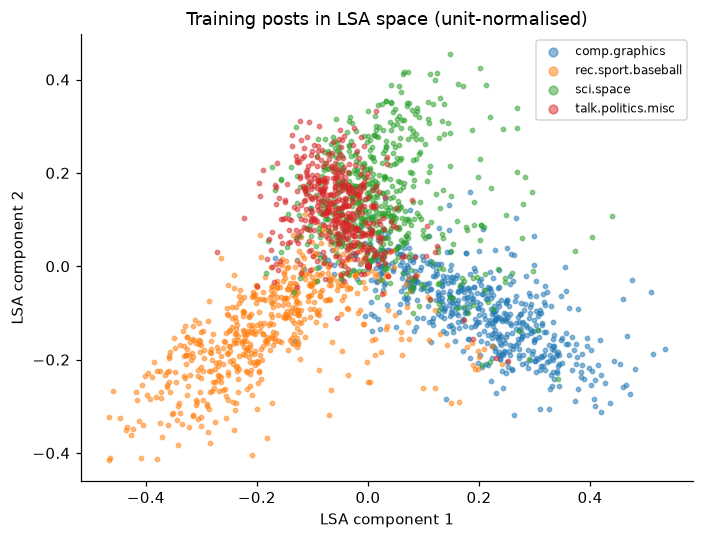

In [7]:
colors = {"comp.graphics": "tab:blue", "rec.sport.baseball": "tab:orange",
          "sci.space": "tab:green", "talk.politics.misc": "tab:red"}
Zn = normalize(Z_train)                       # cosine geometry: unit-length rows
fig, ax = plt.subplots(figsize=(6.5, 5))
for cat, col in colors.items():
    m = y_train == cat
    ax.scatter(Zn[m, 1], Zn[m, 2], s=8, alpha=0.5, color=col, label=cat)
ax.set_xlabel("LSA component 1"); ax.set_ylabel("LSA component 2")
ax.set_title("Training posts in LSA space (unit-normalised)")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.savefig(DOCS / "07_lsa_scatter.png", bbox_inches="tight"); plt.show()

Component 1 separates baseball posts (left) from graphics posts (right); component 2 lifts space and
politics posts to the top, where they still overlap — just as the table above showed component 2 grouping
space and politics words together. Other components separate them further.

### Words become similar too
The rows of $V_k^\top$ (scaled by $\Sigma_k$) give every *word* a dense vector. Words that occur in similar
documents now have high cosine similarity even if they never appear together.

In [8]:
word_vecs = normalize(svd.components_.T * svd.singular_values_)   # one row per word
w2i = {w: i for i, w in enumerate(vocab)}
def lsa_sim(a, b):
    return float(word_vecs[w2i[a]] @ word_vecs[w2i[b]])
for a, b in [("rocket", "launch"), ("rocket", "pitcher"), ("image", "jpeg"), ("tax", "government")]:
    print(f"LSA cosine({a}, {b}) = {lsa_sim(a, b):+.3f}")

def lsa_neighbours(word, n=8):
    s = word_vecs @ word_vecs[w2i[word]]
    return [vocab[i] for i in np.argsort(-s)[1:n + 1]]
for w in ["rocket", "pitcher", "image", "tax"]:
    print(f"{w:>8}:", ", ".join(lsa_neighbours(w)))

LSA cosine(rocket, launch) = +0.417
LSA cosine(rocket, pitcher) = -0.029
LSA cosine(image, jpeg) = +0.534
LSA cosine(tax, government) = +0.152
  rocket: hobby, engine, faa, tripoli, rocketry, thrust, persuade, amateur
 pitcher: sheffield, gwynn, cy, mcgriff, howe, morgan, alex, guzman
   image: vincent, intro, visual, text, arithmetic, contrib, fourier, database
     tax: income, vat, consumer, revenue, raise, sale, dozen, freeze


### Does LSA help retrieval?
Repeat notebook 06's experiment: for every test post, retrieve the 10 most similar training posts and
measure the fraction with the same topic (**precision@10**), using TF-IDF cosine or LSA cosine.

In [9]:
def precision_at_k(S, y_query, k=10):
    order = np.argsort(-S, axis=1)[:, :k]
    return (y_train[order] == y_query[:, None]).mean()

keep = np.asarray(W_test.sum(axis=1)).ravel() > 0
p_tfidf = precision_at_k(cosine_similarity(W_test[keep], W_train), y_test[keep])
p_lsa = precision_at_k(cosine_similarity(Z_test[keep], Z_train), y_test[keep])
print(f"evaluated on {keep.sum():,} test posts")
print(f"TF-IDF ({W_train.shape[1]:,} dims) + cosine: precision@10 = {p_tfidf:.3f}")
print(f"LSA    ({Z_train.shape[1]} dims)  + cosine: precision@10 = {p_lsa:.3f}")

evaluated on 1,438 test posts
TF-IDF (4,400 dims) + cosine: precision@10 = 0.738
LSA    (100 dims)  + cosine: precision@10 = 0.775


With 30 times fewer dimensions, LSA retrieves *more* same-topic posts than raw TF-IDF (0.775 vs 0.738;
notebook 06 reported 0.744 for TF-IDF with a slightly different vocabulary, `min_df=2`). Merging
co-occurring words into shared dimensions lets posts match even when they use different words.
Exercise 1 explores how the number of dimensions matters.

## 3 · Latent Dirichlet Allocation (LDA)
LDA is a **generative probabilistic model**. It imagines that each document was written like this:
1. pick a mixture of topics for the document, $\theta_d \sim \text{Dirichlet}(\alpha)$ (e.g. 80% space, 20% politics);
2. for every word position, pick a topic $z \sim \theta_d$, then pick a word from that topic's word distribution $\beta_z$.

Fitting LDA inverts this story: from word counts alone it estimates the topics $\beta$ (distributions over
words) and each document's mixture $\theta_d$. Unlike LSA, everything is a probability, so topics and
mixtures are non-negative and easy to read. LDA works on raw **counts**, not TF-IDF.

In [10]:
cv = CountVectorizer(analyzer=identity, min_df=5, max_df=0.5)
X_train = cv.fit_transform(train_tok)
X_test = cv.transform(test_tok)
cv_vocab = cv.get_feature_names_out()

lda = LatentDirichletAllocation(n_components=4, learning_method="batch", max_iter=30, random_state=0)
theta_train = lda.fit_transform(X_train)      # document-topic mixtures (rows sum to 1)
theta_test = lda.transform(X_test)
beta = lda.components_ / lda.components_.sum(axis=1, keepdims=True)   # topic-word distributions
print("document-topic matrix:", theta_train.shape, " topic-word matrix:", beta.shape)
print(f"perplexity on the test posts: {lda.perplexity(X_test):,.0f}")

document-topic matrix: (2239, 4)  topic-word matrix: (4, 4400)


perplexity on the test posts: 1,693


In [11]:
pd.DataFrame({f"topic {k}": cv_vocab[np.argsort(-beta[k])[:12]] for k in range(4)})

,topic 0,topic 1,topic 2,topic 3
0,space,year,would,image
1,launch,game,think,file
2,nasa,get,say,use
3,satellite,team,go,graphic
4,orbit,run,people,program
5,system,think,make,format
6,earth,hit,get,software
7,mission,player,know,data
8,year,one,one,jpeg
9,use,would,mr,mail


Without ever seeing a label, LDA has found four word distributions, and reading their top words each one
is recognisably one of the newsgroups: space (topic 0), baseball (topic 1), politics (topic 2, with *mr* and
*president* from the White House press briefings) and graphics (topic 3). Let us draw them.

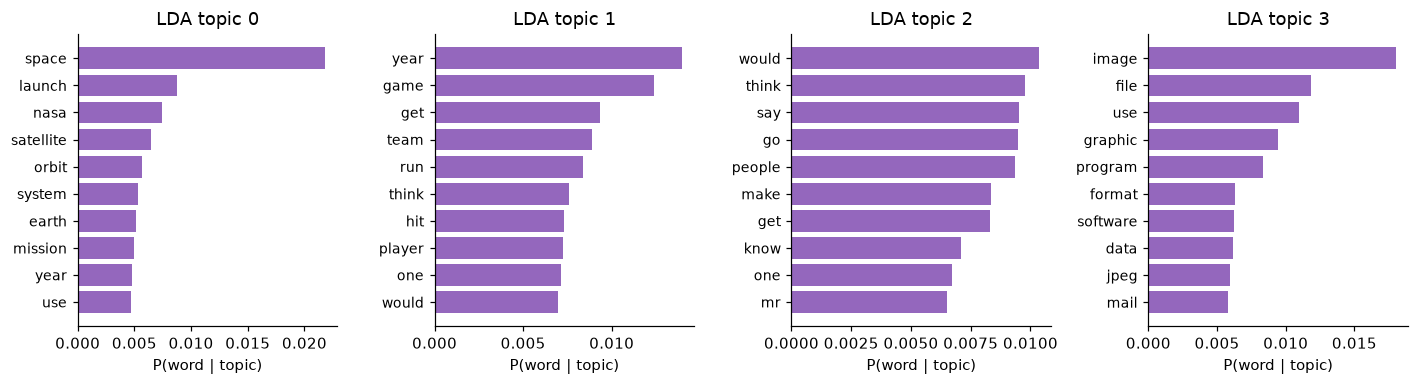

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for k, ax in enumerate(axes):
    top = np.argsort(-beta[k])[:10][::-1]
    ax.barh(cv_vocab[top], beta[k, top], color="tab:purple")
    ax.set_title(f"LDA topic {k}"); ax.tick_params(axis="y", labelsize=9)
    ax.set_xlabel("P(word | topic)")
plt.tight_layout(); plt.savefig(DOCS / "07_lda_topics.png", bbox_inches="tight"); plt.show()

### Topics vs the real categories
Assign each test post to its most probable topic and cross-tabulate with the true newsgroup.

In [13]:
dominant = theta_test.argmax(axis=1)
ct = pd.crosstab(pd.Series(y_test, name="true category"), pd.Series(dominant, name="dominant LDA topic"))
ct

dominant LDA topic,0,1,2,3
true category,,,,
comp.graphics,13,5,32,339
rec.sport.baseball,20,307,54,16
sci.space,202,10,145,37
talk.politics.misc,18,9,279,4


Graphics, baseball and politics posts mostly land in "their" topic. `sci.space` splits: 202 posts go to
the space topic, but 145 go to topic 2 — the discussion topic of *would, think, people* — because many
space posts are debates about NASA funding and policy rather than technical reports.

topic → category: {3: 'comp.graphics', 1: 'rec.sport.baseball', 0: 'sci.space', 2: 'talk.politics.misc'}
test posts whose dominant topic matches their category: 75.6%


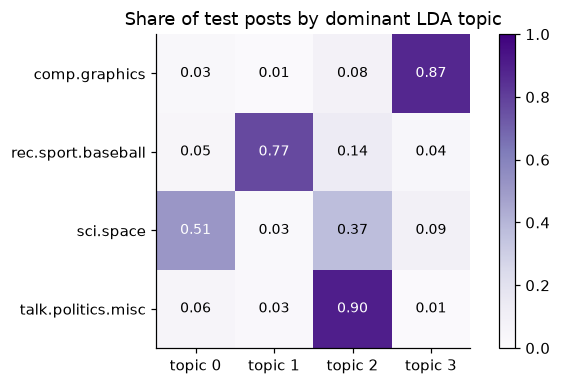

In [14]:
from scipy.optimize import linear_sum_assignment
rows, cols = linear_sum_assignment(-ct.to_numpy())        # best one-to-one topic ↔ category matching
mapping = {int(ct.columns[c]): ct.index[r] for r, c in zip(rows, cols)}
print("topic → category:", mapping)
acc = np.mean([mapping[t] == y for t, y in zip(dominant, y_test)])
print(f"test posts whose dominant topic matches their category: {acc:.1%}")

share = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(5.8, 3.6))
im = ax.imshow(share.to_numpy(), cmap="Purples", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels([f"topic {c}" for c in share.columns])
ax.set_yticks(range(4)); ax.set_yticklabels(share.index)
for i in range(4):
    for j in range(4):
        v = share.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=9)
ax.set_title("Share of test posts by dominant LDA topic")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(DOCS / "07_lda_topic_category.png", bbox_inches="tight"); plt.show()

### A document is a mixture
LDA does not force a single topic per document. Among test posts with at least 50 known words, here are
the most clear-cut one and the most mixed one:

In [15]:
def snippet(text, n=120):
    return " ".join(text.split())[:n] + "…"
n_words = np.asarray(X_test.sum(axis=1)).ravel()
mix = np.where(n_words >= 50, theta_test.max(axis=1), np.nan)   # only posts with at least 50 known words
for i in [int(np.nanargmax(mix)), int(np.nanargmin(mix))]:
    print(f"[{y_test[i]}]  topic mixture = {np.round(theta_test[i], 2)}")
    print("   ", snippet(test["text"][i]), "\n")

[comp.graphics]  topic mixture = [0. 0. 0. 1.]
    Archive-name: jpeg-faq Last-modified: 2 May 1993 This FAQ article discusses JPEG image compression. Suggestions for addi… 

[talk.politics.misc]  topic mixture = [0.26 0.2  0.32 0.23]
    No, this is not true. the CNN pictures show two sites clearly and a third is barely distinguished. If you have a tape yo… 



The JPEG FAQ belongs entirely to the graphics topic, while a short argumentative political reply spreads its
probability over all four topics (largest share, 0.32, on the politics/discussion topic).

## 4 · LSA vs LDA at a glance

| | LSA | LDA |
|---|---|---|
| Input | TF-IDF (or counts) | raw counts |
| Method | linear algebra: truncated SVD | probabilistic generative model |
| Components | orthogonal directions, positive *and* negative loadings | probability distributions over words |
| Document vector | real-valued coordinates | topic proportions that sum to 1 |
| Strength | fast, deterministic, good for retrieval/features | interpretable topics and mixtures |
| Weakness | components are hard to read | slower, results depend on the number of topics and random seed |

Both share the key limitation of the Bag-of-Words family: they ignore word order. They also learn from
document-level co-occurrence only. The next notebook learns dense **word** vectors from local context
windows instead — word2vec.

## Exercises
**Exercise 1.** How many LSA dimensions are needed? Compute test precision@10 with `TruncatedSVD` for
`n_components` in `[2, 5, 10, 25, 50, 100, 200]` and compare with TF-IDF.

In [16]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Two dimensions are not enough (0.571), but only 5 already beat TF-IDF (0.781 vs 0.738). Precision peaks around 10 dimensions (0.802) and slowly declines after that, as extra dimensions bring back word-specific detail that is less useful for telling four broad topics apart.

```python
for k in [2, 5, 10, 25, 50, 100, 200]:
    s = TruncatedSVD(n_components=k, random_state=0).fit(W_train)
    p = precision_at_k(cosine_similarity(s.transform(W_test[keep]), s.transform(W_train)), y_test[keep])
    print(f"k = {k:>3}: precision@10 = {p:.3f}")
print(f"TF-IDF  : precision@10 = {p_tfidf:.3f}")
```
</details>

In [17]:
for k in [2, 5, 10, 25, 50, 100, 200]:
    s = TruncatedSVD(n_components=k, random_state=0).fit(W_train)
    p = precision_at_k(cosine_similarity(s.transform(W_test[keep]), s.transform(W_train)), y_test[keep])
    print(f"k = {k:>3}: precision@10 = {p:.3f}")
print(f"TF-IDF  : precision@10 = {p_tfidf:.3f}")

k =   2: precision@10 = 0.571


k =   5: precision@10 = 0.781


k =  10: precision@10 = 0.802


k =  25: precision@10 = 0.796


k =  50: precision@10 = 0.786


k = 100: precision@10 = 0.775


k = 200: precision@10 = 0.766
TF-IDF  : precision@10 = 0.738


**Exercise 2.** Fit LDA with **8 topics** instead of 4 and print the top 8 words of each topic.
Do some newsgroups split into sub-topics?

In [18]:
# your code here

<details>
<summary><b>Show solution</b></summary>

With more topics than categories, LDA splits broad groups into narrower themes: space science (orbit, moon, probe) vs the space programme (launch, nasa, satellite), and the White House press briefings (mr, stephanopoulos) appear as their own topic. Two topics collect generic conversational words (would, get, think).

```python
lda8 = LatentDirichletAllocation(n_components=8, learning_method="batch", max_iter=30, random_state=0).fit(X_train)
for k, comp in enumerate(lda8.components_):
    print(f"topic {k}:", ", ".join(cv_vocab[np.argsort(-comp)[:8]]))
```
</details>

In [19]:
lda8 = LatentDirichletAllocation(n_components=8, learning_method="batch", max_iter=30, random_state=0).fit(X_train)
for k, comp in enumerate(lda8.components_):
    print(f"topic {k}:", ", ".join(cv_vocab[np.argsort(-comp)[:8]]))

topic 0: space, orbit, earth, mission, lunar, moon, system, probe
topic 1: space, launch, nasa, satellite, technology, year, u, shuttle
topic 2: people, work, job, president, program, government, go, state
topic 3: would, get, think, know, like, go, one, say
topic 4: would, one, make, people, like, right, point, get
topic 5: image, file, use, graphic, program, format, software, jpeg
topic 6: mr, stephanopoulos, president, say, go, think, know, make
topic 7: year, game, team, run, player, hit, get, last


**Exercise 3.** Write a function `describe(text)` that preprocesses a new piece of text and prints its
LDA topic mixture together with each topic's top 5 words. Try it on
`"The shuttle launch was delayed because of a problem with the rocket engine."`

In [20]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
def describe(text):
    theta = lda.transform(cv.transform([nlp_course.preprocess(text)]))[0]
    for k in np.argsort(-theta):
        print(f"{theta[k]:.2f}  topic {k}: {', '.join(cv_vocab[np.argsort(-beta[k])[:5]])}")
describe("The shuttle launch was delayed because of a problem with the rocket engine.")
```
</details>

In [21]:
def describe(text):
    theta = lda.transform(cv.transform([nlp_course.preprocess(text)]))[0]
    for k in np.argsort(-theta):
        print(f"{theta[k]:.2f}  topic {k}: {', '.join(cv_vocab[np.argsort(-beta[k])[:5]])}")
describe("The shuttle launch was delayed because of a problem with the rocket engine.")

0.89  topic 0: space, launch, nasa, satellite, orbit
0.04  topic 2: would, think, say, go, people
0.04  topic 3: image, file, use, graphic, program
0.04  topic 1: year, game, get, team, run


## Summary
- Sparse TF-IDF vectors treat every word as an independent axis, so they cannot see synonymy.
- **LSA** = truncated SVD of the TF-IDF matrix: documents *and* words get dense vectors in a small latent space.
- LSA components are contrasts between groups of co-occurring words; they can be used for retrieval and as features.
- **LDA** models each document as a mixture of topics and each topic as a distribution over words; its topics are easy to read.
- LSA with 100 dimensions beats raw TF-IDF for retrieval (precision@10 0.775 vs 0.738).
- On the four newsgroups, unsupervised LDA topics line up with the real categories for 75.6% of test posts.

**Next:** [08 · Distributional semantics and word2vec](08_word2vec.ipynb).